In [3]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Q1: Sunflower Detection Using Scale-Space Analysis

Range of sigmas: [ 5.          5.35714286  5.71428571  6.07142857  6.42857143  6.78571429
  7.14285714  7.5         7.85714286  8.21428571  8.57142857  8.92857143
  9.28571429  9.64285714 10.        ]


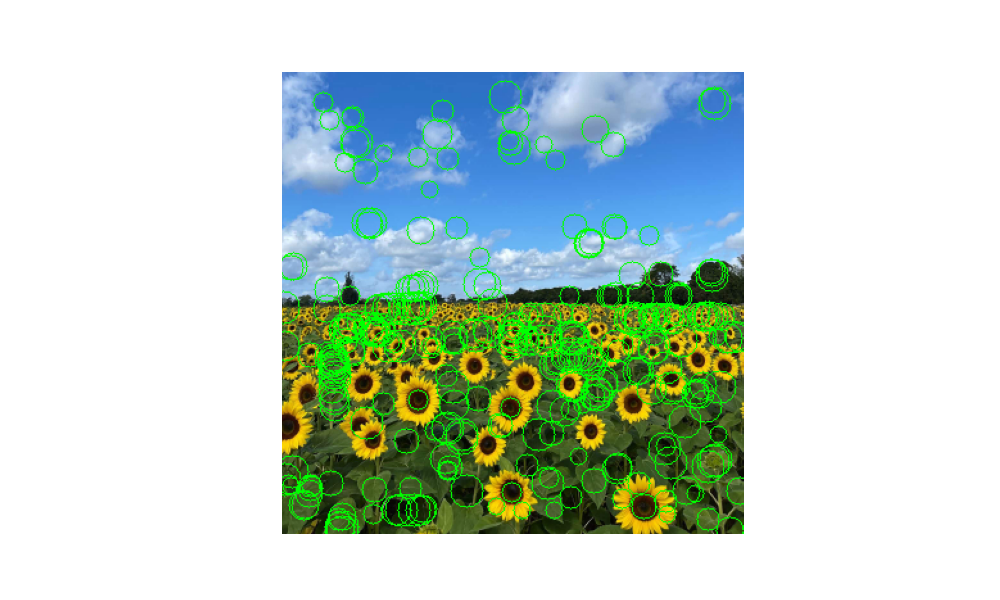

In [4]:
im = cv.imread('Images/the_berry_farms_sunflower_field.jpeg',cv.IMREAD_REDUCED_COLOR_4)
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
sigmas = np.linspace(5.0, 10.0, num=15)
scale_space = []
print(f"Range of sigmas: {sigmas}")

for sigma in sigmas:
    ksize = int(2 * np.ceil(3 * sigma) + 1)  # Define kernel size based on sigma
    blur = cv.GaussianBlur(gray, (ksize, ksize), sigma) # Apply Gaussian blur
    lap = cv.Laplacian(blur, cv.CV_32F) # Apply Laplacian operator
    log_response = (sigma ** 2) * np.abs(lap) # Scale-normalized Laplacian response
    scale_space.append(log_response)

scale_space = np.array(scale_space)
detections = []
threshold = 0.02

for s in range(1, len(sigmas) - 1):
    for y in range(1, gray.shape[0] - 1):
        for x in range(1, gray.shape[1] - 1):
            value = scale_space[s, y, x]
            if value < threshold:
                continue
            neighborhood = scale_space[s - 1:s + 2,y - 1:y + 2,x - 1:x + 2]
            if value == np.max(neighborhood):
                detections.append((y, x, s))

output = im.copy()
for y, x, s in detections:
    sigma = sigmas[s]
    r = int(np.sqrt(2) * sigma)
    cv.circle(output, (x, y), r, (0, 255, 0), 1)

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()


# Q2: Line and Circle Fitting using RANSAC

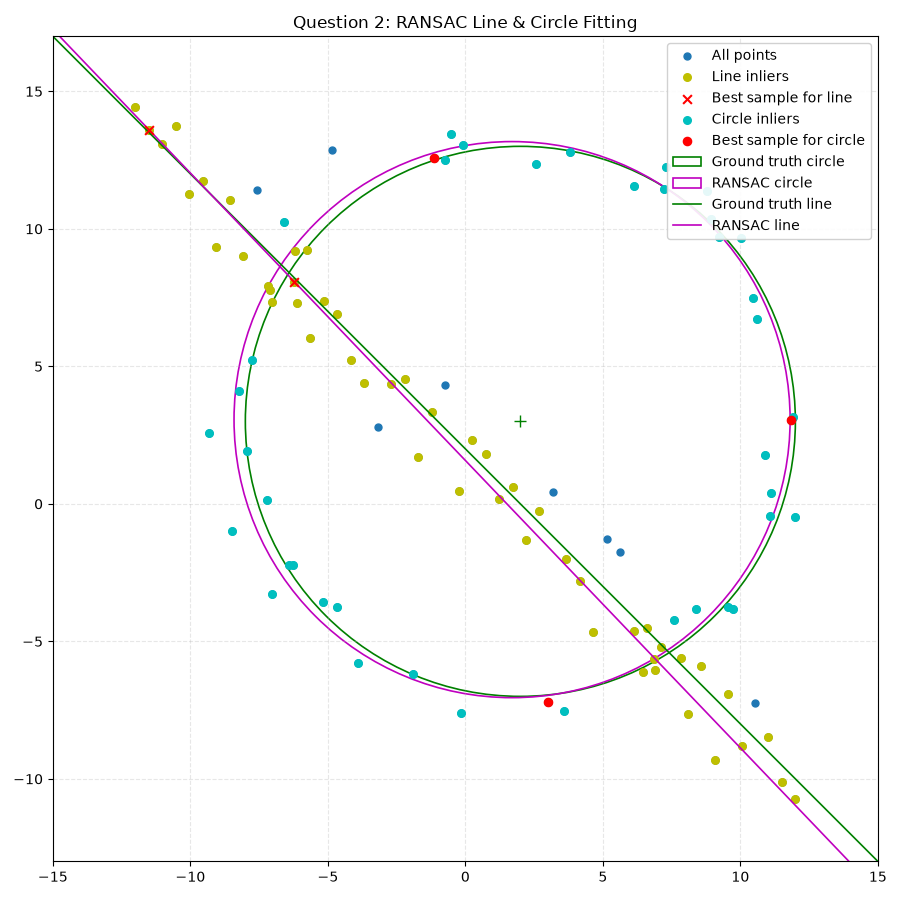

In [5]:
np.random.seed(23)

N = 100
half_n = N // 2
# circle parameters
r_gt = 10.0
x0_gt, y0_gt = 2.0, 3.0
s_circ = r_gt / 16.0
t = np.random.uniform(0, 2 * np.pi, half_n)
n_circ = s_circ * np.random.randn(half_n)
x_circ = x0_gt + (r_gt + n_circ) * np.cos(t)
y_circ = y0_gt + (r_gt + n_circ) * np.sin(t)
X_circ = np.hstack((x_circ.reshape(half_n, 1), y_circ.reshape(half_n, 1)))
# line parameters
s_line = 1.0
m_gt, b_gt = -1.0, 2.0
x_line = np.linspace(-12, 12, half_n)
y_line = m_gt * x_line + b_gt + s_line * np.random.randn(half_n)
X_line = np.hstack((x_line.reshape(half_n, 1), y_line.reshape(half_n, 1)))
# combine circle and line points
X = np.vstack((X_circ, X_line))

# (a) RANSAC line fitting
def ransac_line(pts, max_iters=1000, thresh=1.0):
    best_inliers = []
    best_sample = None
    best_params = None  # (a, b, d)
    n_pts = len(pts)
    
    for _ in range(max_iters):
        idx = np.random.choice(n_pts, 2, replace=False)
        p1, p2 = pts[idx[0]], pts[idx[1]]
        if np.allclose(p1, p2):
            continue
            
        dx = p2[0] - p1[0]
        dy = p2[1] - p1[1]
        norm = np.hypot(dx, dy)
        a = -dy / norm
        b = dx / norm
        d = -(a * p1[0] + b * p1[1])
        
        distances = np.abs(a * pts[:, 0] + b * pts[:, 1] + d)
        inliers = np.where(distances < thresh)[0]
        
        if len(inliers) > len(best_inliers):
            best_inliers = inliers
            best_sample = idx
            best_params = (a, b, d)
            
    return best_params, best_sample, best_inliers
# Run RANSAC line fitting the function defined above(2000times)
line_params, line_sample_idx, line_inlier_idx = ransac_line(X, max_iters=2000, thresh=1.2)

# (b) RANSAC circle fitting on remaining points after line inliers are removed
remnant_mask = np.ones(len(X), dtype=bool)
remnant_mask[line_inlier_idx] = False
remnant_indices = np.where(remnant_mask)[0]
X_remnant = X[remnant_mask]

def fit_circle_3pts(p1, p2, p3):
    temp = p2[0]**2 + p2[1]**2
    bc = (p1[0]**2 + p1[1]**2 - temp) / 2.0
    cd = (temp - p3[0]**2 - p3[1]**2) / 2.0
    det = (p1[0] - p2[0]) * (p2[1] - p3[1]) - (p2[0] - p3[0]) * (p1[1] - p2[1])
    
    if abs(det) < 1e-6: 
        return None
        
    cx = (bc * (p2[1] - p3[1]) - cd * (p1[1] - p2[1])) / det
    cy = ((p1[0] - p2[0]) * cd - (p2[0] - p3[0]) * bc) / det
    rad = np.hypot(p1[0] - cx, p1[1] - cy)
    return cx, cy, rad

def circle_loss(params, pts):
    cx, cy, rad = params
    distances = np.hypot(pts[:, 0] - cx, pts[:, 1] - cy)
    return np.sum((distances - rad) ** 2)

def ransac_circle(pts, max_iters=2000, thresh=1.0):
    best_inliers = []
    best_sample = None
    best_circle = None
    n_pts = len(pts)
    
    for _ in range(max_iters):
        idx = np.random.choice(n_pts, 3, replace=False)
        p1, p2, p3 = pts[idx[0]], pts[idx[1]], pts[idx[2]]
        circle = fit_circle_3pts(p1, p2, p3)
        if circle is None:
            continue
            
        cx, cy, rad = circle
        distances = np.abs(np.hypot(pts[:, 0] - cx, pts[:, 1] - cy) - rad)
        inliers = np.where(distances < thresh)[0]
        
        if len(inliers) > len(best_inliers):
            best_inliers = inliers
            best_sample = idx
            best_circle = (cx, cy, rad)
            
    inlier_pts = pts[best_inliers]
    res = minimize(circle_loss, x0=best_circle, args=(inlier_pts,), method='Nelder-Mead')
    refined_circle = res.x
    
    return refined_circle, best_sample, best_inliers

circle_params, circle_sample_idx, circle_inlier_remnant_idx = ransac_circle(X_remnant, max_iters=2000, thresh=1.0)
circle_inlier_idx = remnant_indices[circle_inlier_remnant_idx]
circle_sample_orig_idx = remnant_indices[circle_sample_idx]

# display the results
fig, ax = plt.subplots(figsize=(9, 9))

ax.scatter(X[:, 0], X[:, 1], c='#1f77b4', s=25, label='All points', zorder=1)
ax.scatter(X[line_inlier_idx, 0], X[line_inlier_idx, 1], c='y', s=30, label='Line inliers', zorder=2)
ax.scatter(X[line_sample_idx, 0], X[line_sample_idx, 1], c='r', marker='x', s=40, label='Best sample for line', zorder=5)
ax.scatter(X[circle_inlier_idx, 0], X[circle_inlier_idx, 1], c='c', s=30, label='Circle inliers', zorder=2)
ax.scatter(X[circle_sample_orig_idx, 0], X[circle_sample_orig_idx, 1], c='r', marker='o', s=35, label='Best sample for circle', zorder=5)
gt_circle_patch = plt.Circle((x0_gt, y0_gt), r_gt, color='g', fill=False, linewidth=1.2, label='Ground truth circle')
ax.add_patch(gt_circle_patch)
ax.plot(x0_gt, y0_gt, '+', color='g', markersize=8)

ransac_circle_patch = plt.Circle((circle_params[0], circle_params[1]), circle_params[2], color='m', fill=False, linewidth=1.2, label='RANSAC circle')
ax.add_patch(ransac_circle_patch)

x_vals = np.array([-15, 15])
y_gt_vals = m_gt * x_vals + b_gt
ax.plot(x_vals, y_gt_vals, color='g', linewidth=1.2, label='Ground truth line')

a, b_line, d = line_params
y_ransac_vals = (-a * x_vals - d) / b_line
ax.plot(x_vals, y_ransac_vals, color='m', linewidth=1.2, label='RANSAC line')

ax.set_aspect('equal')
ax.set_xlim(-15, 15)
ax.set_ylim(-13, 17)
ax.legend(loc='upper right', framealpha=0.9)
plt.title('Question 2: RANSAC Line & Circle Fitting')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

**(d) What will happen if we fit the circle first?**

If we fit the circle first we can see some line points may be incorrectly classified as circle inliers. Then removing these points could reduce the number of line inliers, making the subsequent line fitting less accurate.

In [6]:
%matplotlib widget
import matplotlib.pyplot as plt

print(plt.get_backend())

widget


Click 4 corners in this order: top-left, top-right, bottom-right, bottom-left.


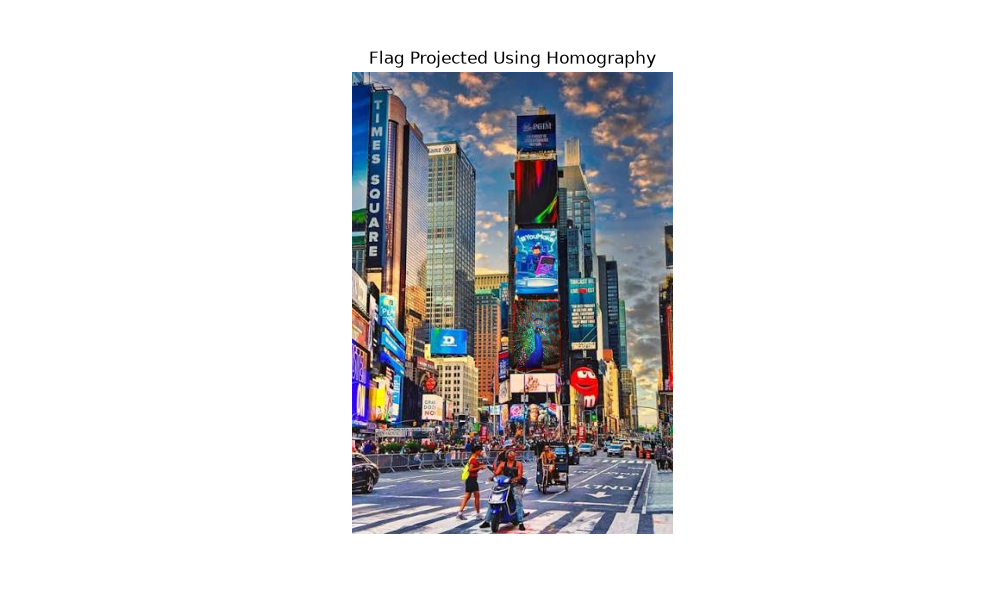

In [ ]:
background_bgr = cv.imread("/home/lasan-perera/University(Aca)/EN3160-assignment-2/Images/wadham.jpg")
overlay_bgr = cv.imread("/home/lasan-perera/University(Aca)/EN3160-assignment-2/Images/flag.png")
# background_bgr = cv.imread("/home/lasan-perera/University(Aca)/EN3160-assignment-2/Images/train.jpg")
# overlay_bgr = cv.imread("/home/lasan-perera/University(Aca)/EN3160-assignment-2/Images/sri lanka.jpeg")
# background_bgr = cv.imread("/home/lasan-perera/University(Aca)/EN3160-assignment-2/Images/tokyo.jpeg")
# overlay_bgr = cv.imread("/home/lasan-perera/University(Aca)/EN3160-assignment-2/Images/peacock.jpg")
display_img = background_bgr.copy()
points = []

def select_point(event, x, y, flags, param):
    if event == cv.EVENT_LBUTTONDOWN and len(points) < 4:
        points.append([x, y])
        cv.circle(display_img, (x, y), 6, (0, 255, 0), -1)
        cv.putText(
            display_img, str(len(points)), (x + 8, y - 8),
            cv.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2
        )
        cv.imshow("Select 4 corners", display_img)

cv.namedWindow("Select 4 corners", cv.WINDOW_NORMAL)
cv.imshow("Select 4 corners", display_img)
cv.setMouseCallback("Select 4 corners", select_point)
print("Click 4 corners in this order: top-left, top-right, bottom-right, bottom-left.")

while len(points) < 4:
    if cv.waitKey(20) & 0xFF == 27:  # Esc to cancel
        cv.destroyAllWindows()
        raise RuntimeError("Point selection cancelled.")

cv.destroyAllWindows()

dst_pts = np.float32(points)

h, w = overlay_bgr.shape[:2]
src_pts = np.float32([
    [0, 0],
    [w - 1, 0],
    [w - 1, h - 1],
    [0, h - 1]
])

H = cv.getPerspectiveTransform(src_pts, dst_pts)
warped = cv.warpPerspective(
    overlay_bgr, H,
    (background_bgr.shape[1], background_bgr.shape[0])
)
mask_src = np.full((h, w), 255, dtype=np.uint8)
mask = cv.warpPerspective(
    mask_src, H,
    (background_bgr.shape[1], background_bgr.shape[0])
)
mask = mask > 0

alpha = 0.9 #opacity of the flag (60% flag, 40% background)
result = background_bgr.copy()
result[mask] = cv.addWeighted(background_bgr, 1 - alpha,warped, alpha, 0)[mask]

result_rgb = cv.cvtColor(result, cv.COLOR_BGR2RGB)
plt.figure(figsize=(10, 6))
plt.imshow(result_rgb)
plt.title("Flag Projected Using Homography")
plt.axis("off")
plt.show()


**Rationale for Image Selection:**

Three image pairs were selected: Wadham College with the British flag(provided one), Tokyo with Sri Lankan peacock, and a train with a visit Sri Lankan image. These pairs were chosen to demonstrate how homography can transform and project different images onto selected regions of a background. These images contain flat surfaces and then we can easily project another image.